## **1. Import Libraries & Load Data**

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import datetime as dt

delay_dataset = pd.read_csv('TTC_Bus_Delays_2021_2026_with_outliers.csv')

## **2. Delay Duration Distribution**

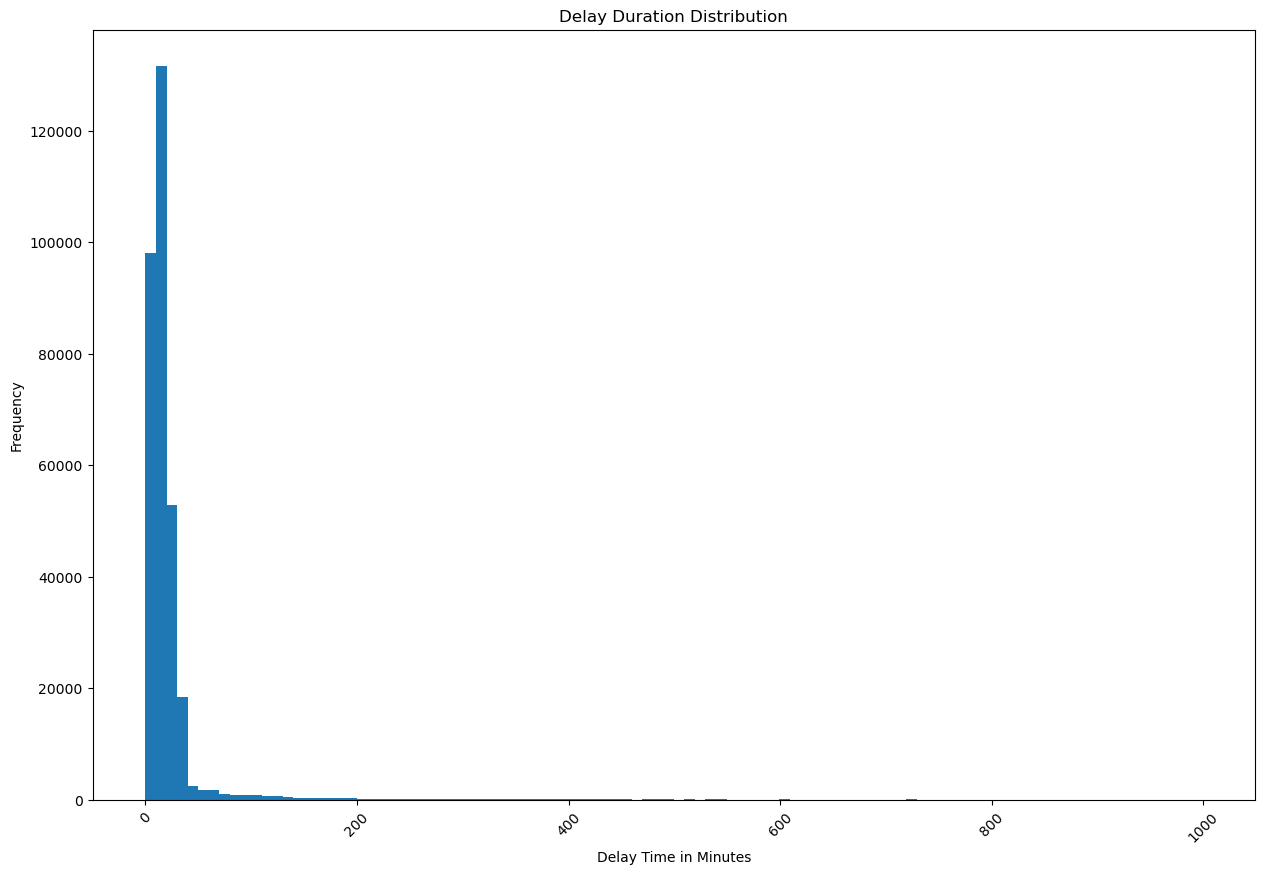

In [21]:
plt.figure(figsize = (15,10))
plt.hist(list(delay_dataset['Min Delay']), bins=100)

plt.xticks(fontsize = 10, rotation = 45)

plt.xlabel('Delay Time in Minutes')
plt.ylabel('Frequency')
plt.title('Delay Duration Distribution')
plt.show()

## **3. Average Delay by Incident**

Incident
Held By Parades/Marches                         122.73
Diversion                                       117.71
Road Blocked - Non-TTC Collision                 70.58
Collision/Personal Injury - TTC Not Involved     58.10
Held By                                          53.28
Overhead                                         46.35
MFAFR                                            33.77
Weather Related                                  28.82
Late Leaving Garage - Operations                 28.50
Late Vehicle – Route                             26.00
Name: Min Delay, dtype: float64
--------------------------------------------------


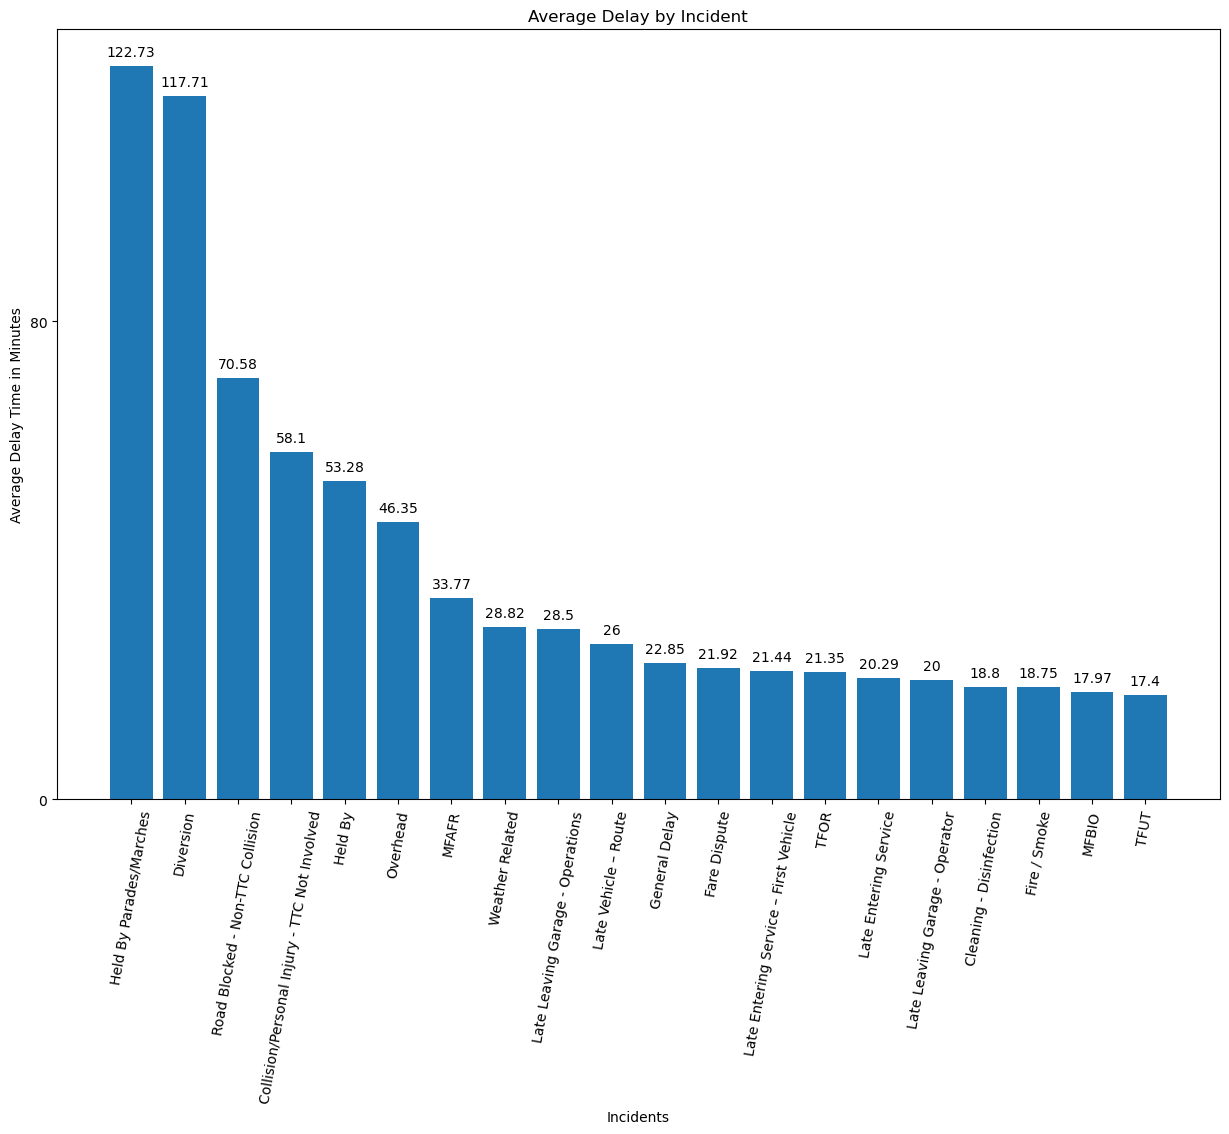

In [3]:
average_delay_by_incident = (
    delay_dataset.groupby(['Incident'])['Min Delay'].mean().round(2)
    .sort_values(ascending=False)
)
print(average_delay_by_incident.head(10))
print("-"*50)

plt.figure(figsize = (15,10))
bars = plt.bar(average_delay_by_incident.head(20).index, average_delay_by_incident.head(20).values)

plt.bar_label(bars, padding=5)

plt.xticks(fontsize = 10, rotation = 80)
plt.yticks(range(0, 81, 80))

plt.xlabel('Incidents')
plt.ylabel('Average Delay Time in Minutes')

plt.title('Average Delay by Incident')
plt.show()

## **4. Median Delay by Route**

Route
LINE SHUTTLE    49.0
445             40.0
5               30.0
363             30.0
172             30.0
352             30.0
353             30.0
169             30.0
354             30.0
167             30.0
Name: Min Delay, dtype: float64
--------------------------------------------------


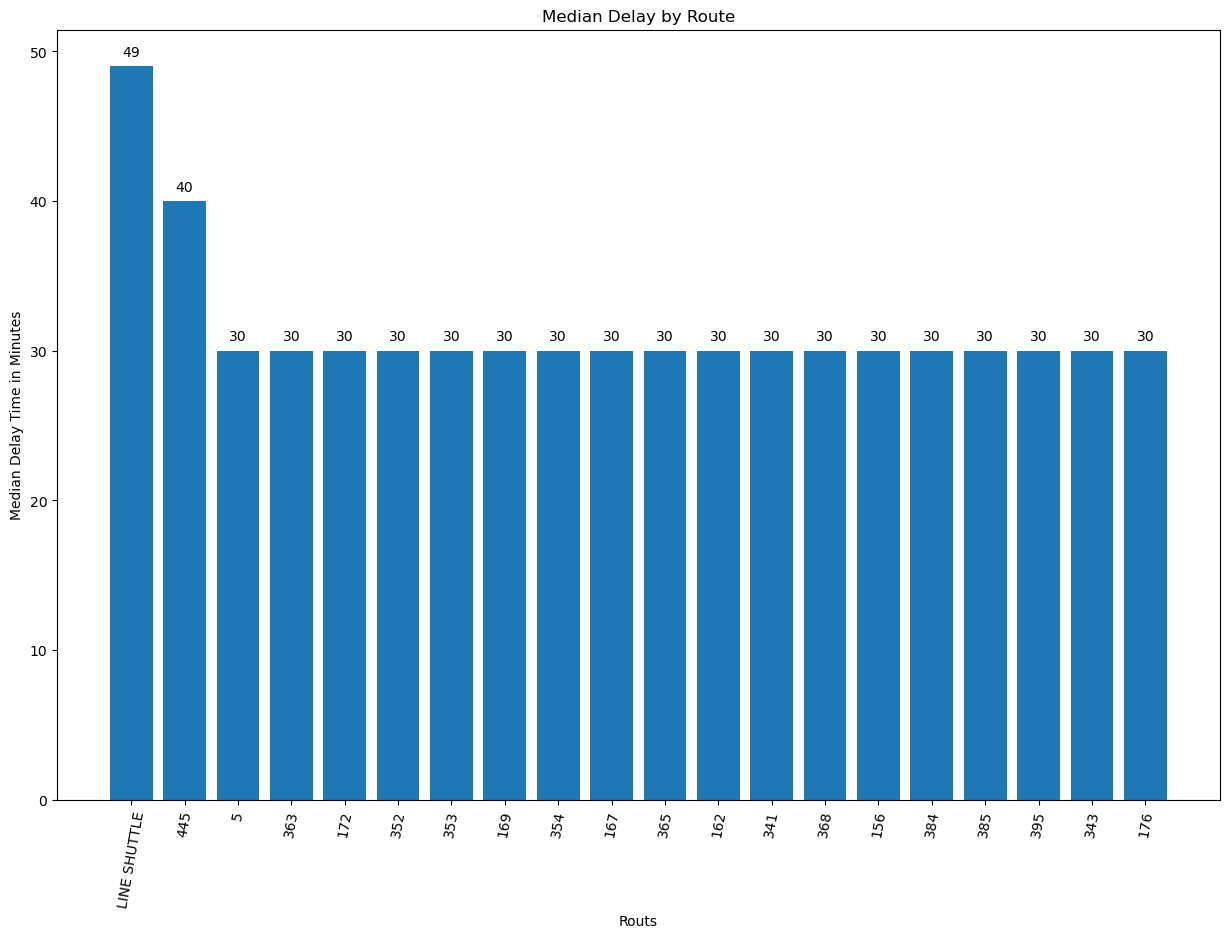

In [4]:
median_delay_by_route = (
    delay_dataset
    .groupby(['Route'])['Min Delay'].median()
    .sort_values(ascending=False)
)
print(median_delay_by_route.head(10))
print("-"*50)

plt.figure(figsize = (15,10))
bars = plt.bar(median_delay_by_route.head(20).index, median_delay_by_route.head(20).values)

plt.bar_label(bars, padding=5)

plt.xticks(fontsize = 10, rotation = 80)
plt.yticks(range(0, 51, 10))

plt.xlabel('Routs')
plt.ylabel('Median Delay Time in Minutes')

plt.title('Median Delay by Route')
plt.show()

## **5. Incident Count by Route for the 20 Routes with the Highest Median Delays**

              Median_Delay  Incident_Count
Route                                     
LINE SHUTTLE          49.0               1
445                   40.0               1
5                     30.0              61
363                   30.0             152
172                   30.0              82
352                   30.0             181
353                   30.0             249
169                   30.0             775
354                   30.0             146
167                   30.0             378
--------------------------------------------------


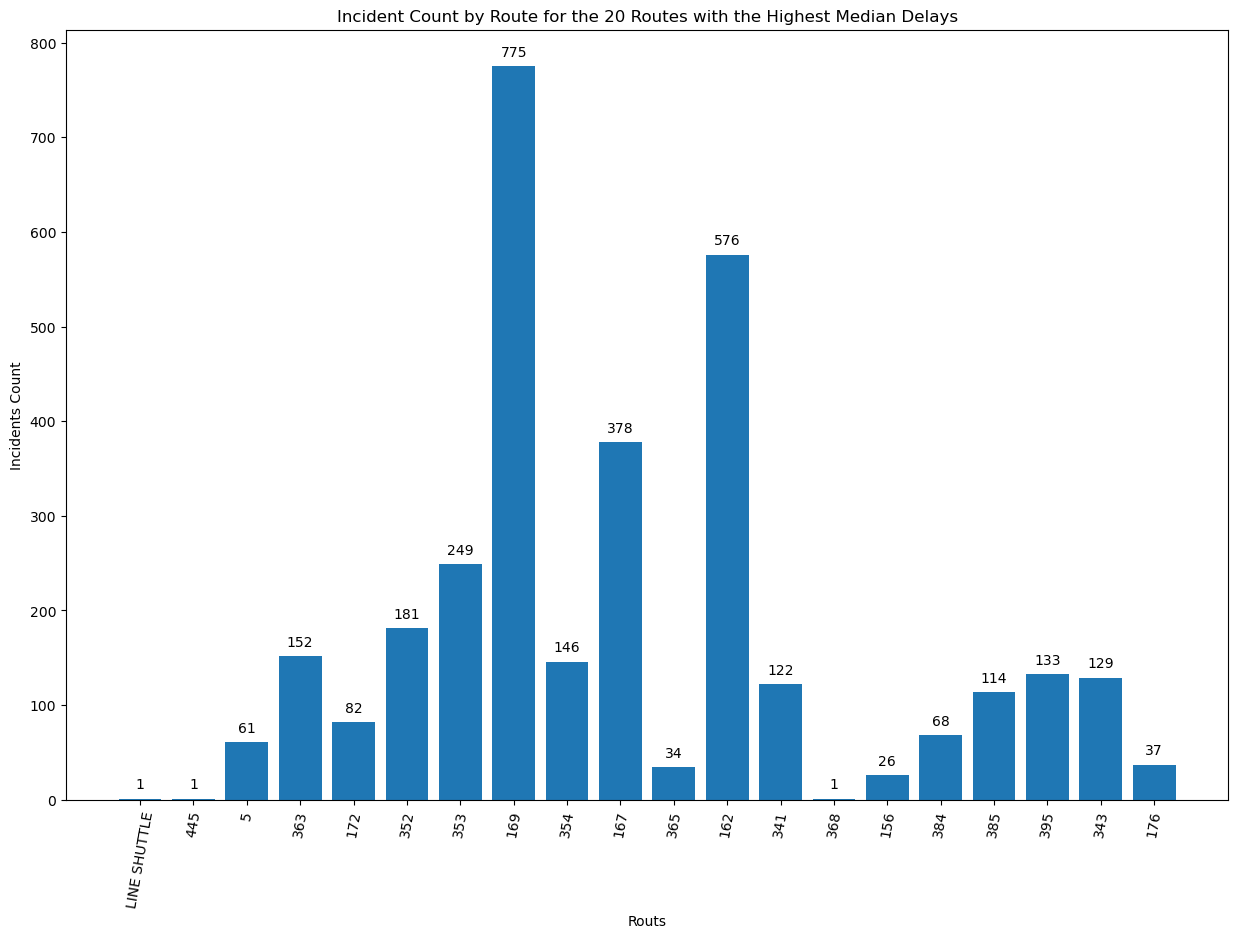

In [19]:
incident_count_by_route = (
    delay_dataset
    .groupby(['Route'])['Min Delay']
    .agg(
        Median_Delay='median',
        Incident_Count='count'
    )
    .sort_values('Median_Delay', ascending=False)
)
print(incident_count_by_route.head(10))
print("-"*50)

plt.figure(figsize = (15,10))
bars = plt.bar(incident_count_by_route.head(20).index, incident_count_by_route.head(20)['Incident_Count'])

plt.bar_label(bars, padding=5)

plt.xticks(fontsize = 10, rotation = 80)
plt.yticks(range(0, 801, 100))

plt.xlabel('Routs')
plt.ylabel('Incidents Count')

plt.title('Incident Count by Route for the 20 Routes with the Highest Median Delays')
plt.show()

## **6. Median Bus Delay by Time Period**

0                 Night
1         Early morning
2         Early morning
3         Early morning
4         Early morning
              ...      
317753            Night
317754            Night
317755            Night
317756            Night
317757            Night
Name: Time_Period, Length: 317758, dtype: string


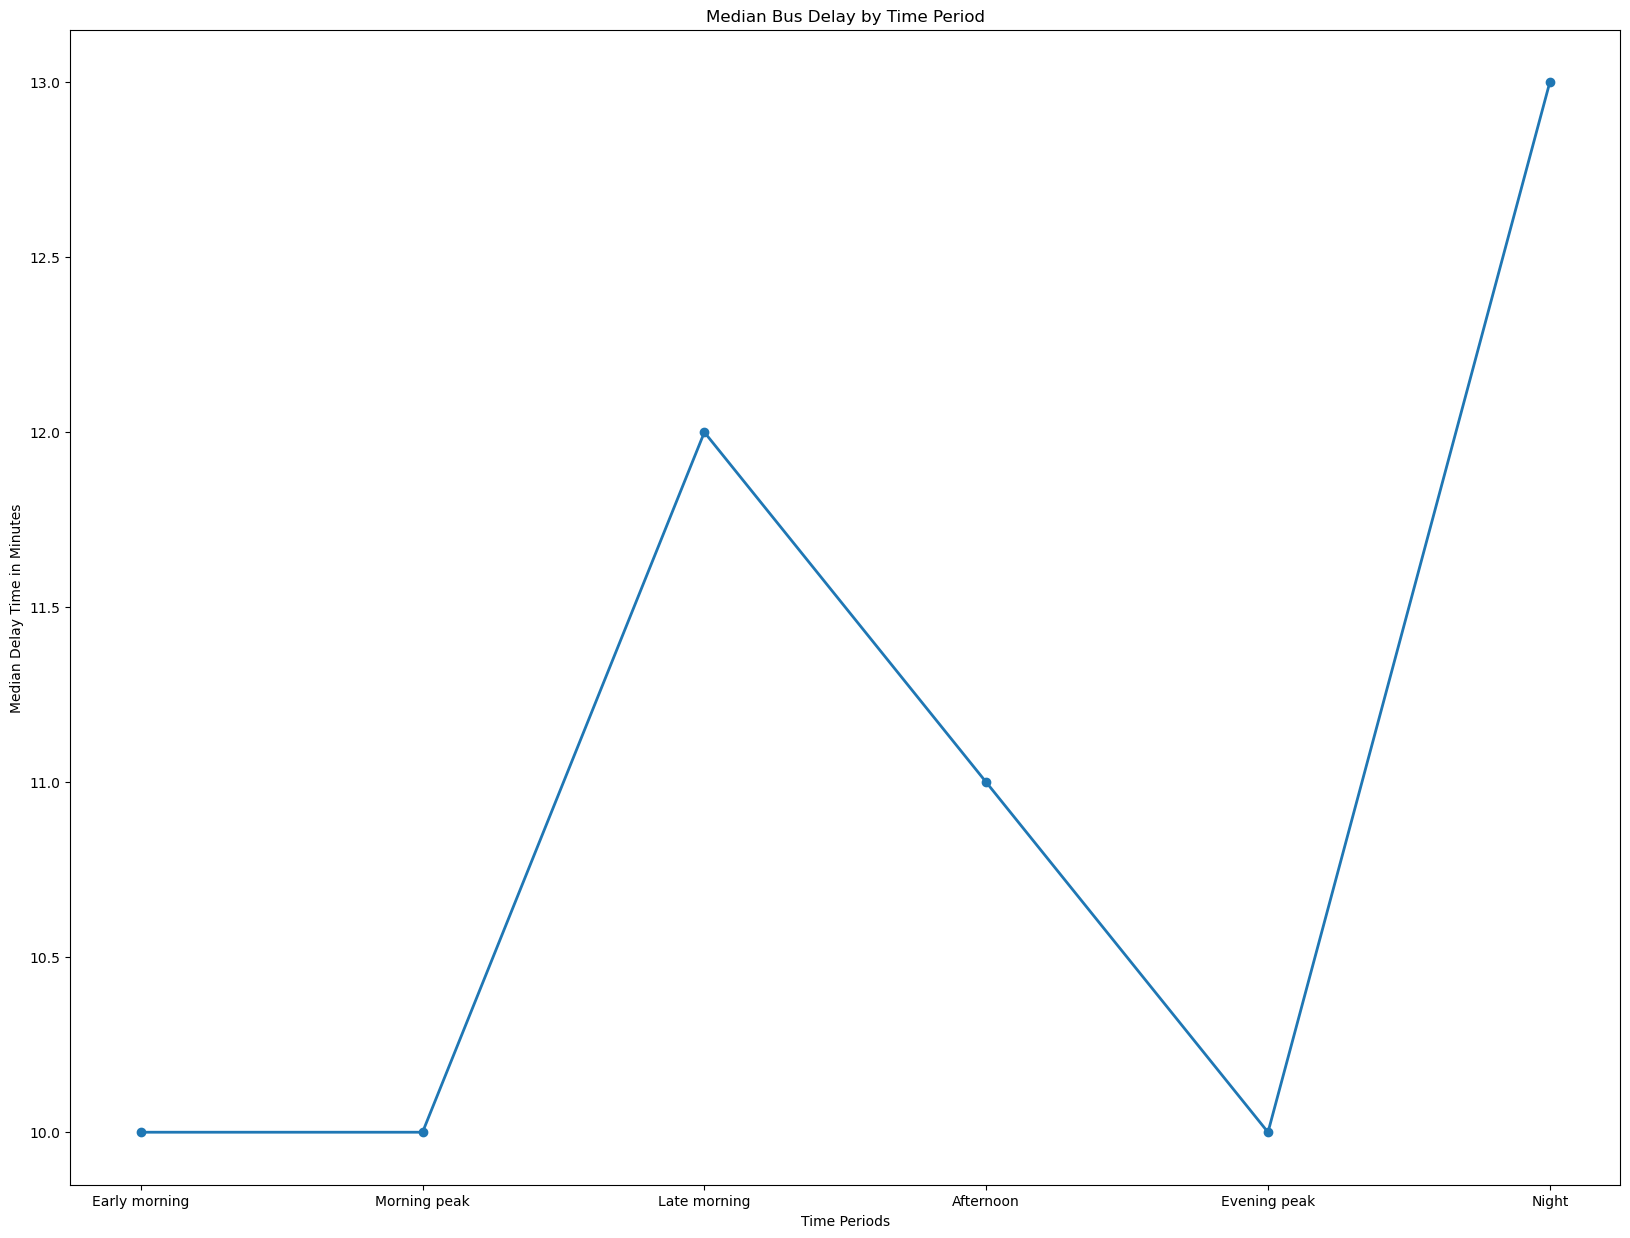

In [20]:
# Convert Time to datetime and extract the hour
delay_dataset['Hour'] =  pd.to_datetime(
    delay_dataset['Time'].astype(str),
    format='%H:%M',
    errors='coerce'
).dt.hour

time_period_conditions = [
    delay_dataset['Hour'].between(5, 6),
    delay_dataset['Hour'].between(7, 9),
    delay_dataset['Hour'].between(10, 11),
    delay_dataset['Hour'].between(12, 15),
    delay_dataset['Hour'].between(16, 18),
    (delay_dataset['Hour'] >= 19) | (delay_dataset['Hour'] <= 4)
]

periods = ['Early morning', 'Morning peak', 'Late morning', 'Afternoon', 'Evening peak', 'Night']

delay_dataset['Time_Period'] = pd.Series(pd.NA, index=delay_dataset.index, dtype='string')

for index in range(len(time_period_conditions)):
    delay_dataset.loc[time_period_conditions[index], 'Time_Period'] = periods[index]

print(delay_dataset['Time_Period'])

fig, ax = plt.subplots(figsize = (20, 15))

median_delay_by_period = delay_dataset.groupby('Time_Period', observed=True)['Min Delay'].median().reindex(periods)

ax.plot(median_delay_by_period.index, median_delay_by_period.values, marker='o', linewidth=2)  
ax.set_xlabel('Time Periods')
ax.set_ylabel('Median Delay Time in Minutes')
ax.set_title('Median Bus Delay by Time Period')

plt.show()

## **7. The Relationship Between Delay Times in Minutes and Time Between Buses**

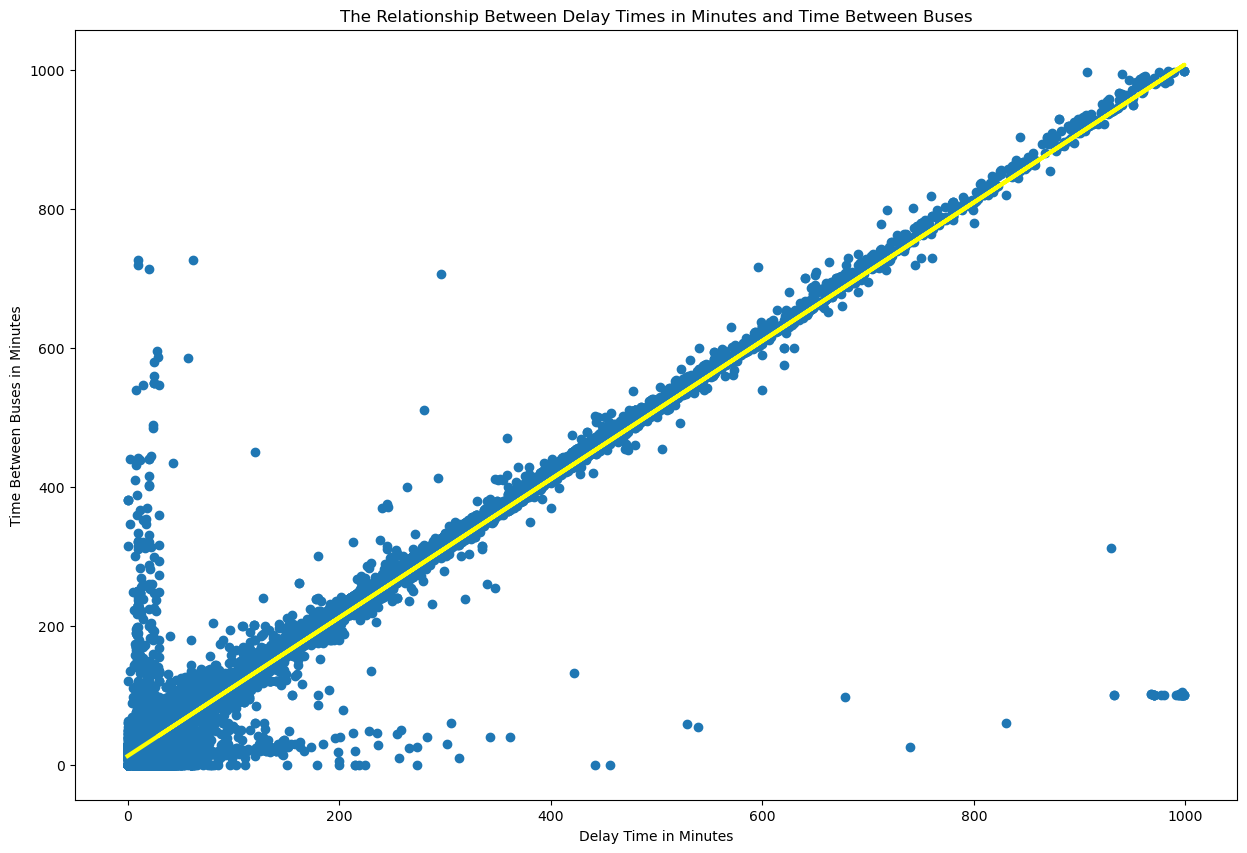

In [9]:
plt.figure(figsize= (15, 10))
plt.scatter(delay_dataset['Min Delay'], delay_dataset['Min Gap']);
plt.title("The Relationship Between Delay Times in Minutes and Time Between Buses")

plt.xlabel('Delay Time in Minutes')
plt.ylabel('Time Between Buses in Minutes');

coefficients = np.polyfit(delay_dataset['Min Delay'], delay_dataset['Min Gap'], 1)

trend_line = np.poly1d(coefficients)
plt.plot(delay_dataset['Min Delay'], trend_line(delay_dataset['Min Delay']), color='yellow', linewidth=3);
plt.show()

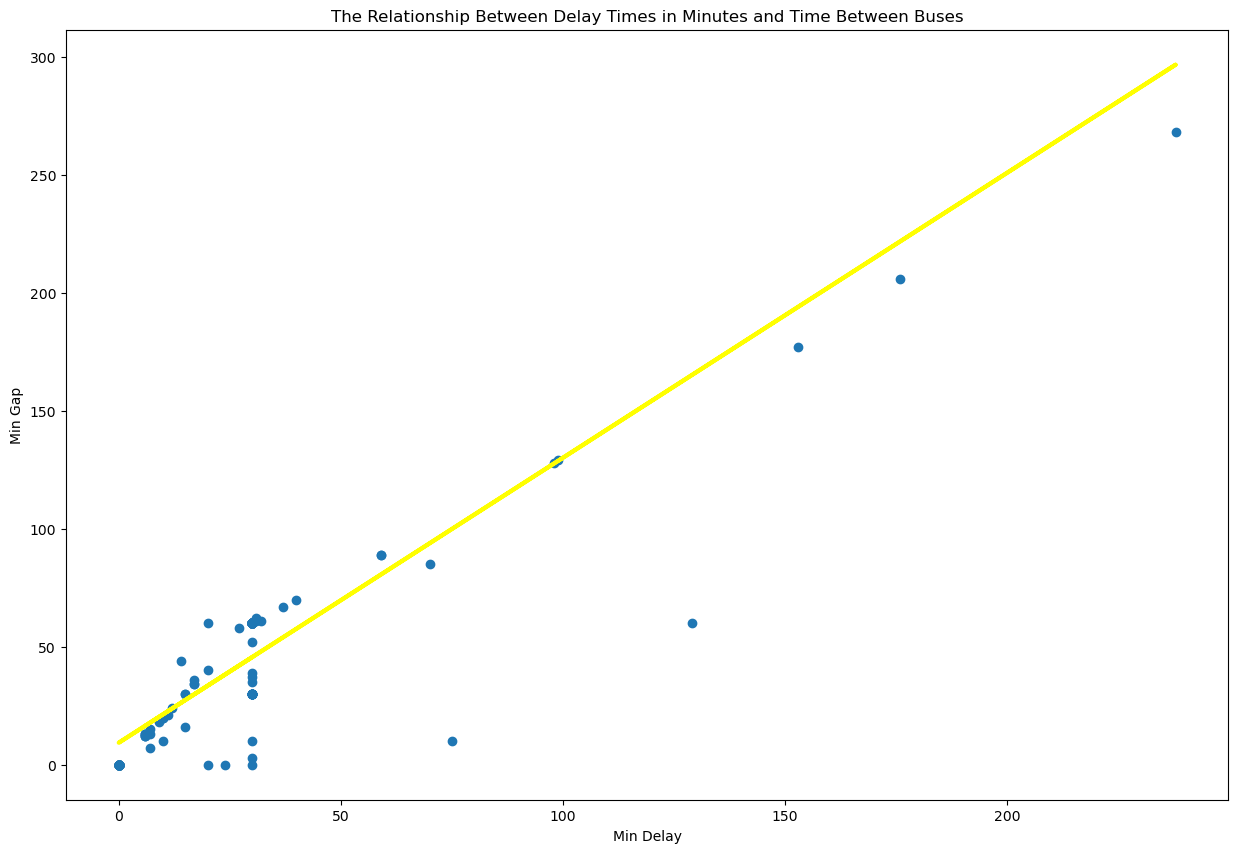

In [22]:
#Extra graph to prove that it did not come by chance but it is proved for each single route
plt.figure(figsize= (15, 10))

one_route = delay_dataset.loc[delay_dataset['Route'] == '353']

plt.scatter(one_route['Min Delay'], one_route['Min Gap']);
plt.title("The Relationship Between Delay Times in Minutes and Time Between Buses")

plt.xlabel('Min Delay')
plt.ylabel('Min Gap');

coefficients = np.polyfit(one_route['Min Delay'], one_route['Min Gap'], 1)

trend_line = np.poly1d(coefficients)
plt.plot(one_route['Min Delay'], trend_line(one_route['Min Delay']), color='yellow', linewidth=3);
plt.show()

## **8. Heatmap of Numerical features Relevent to Bus Delays**

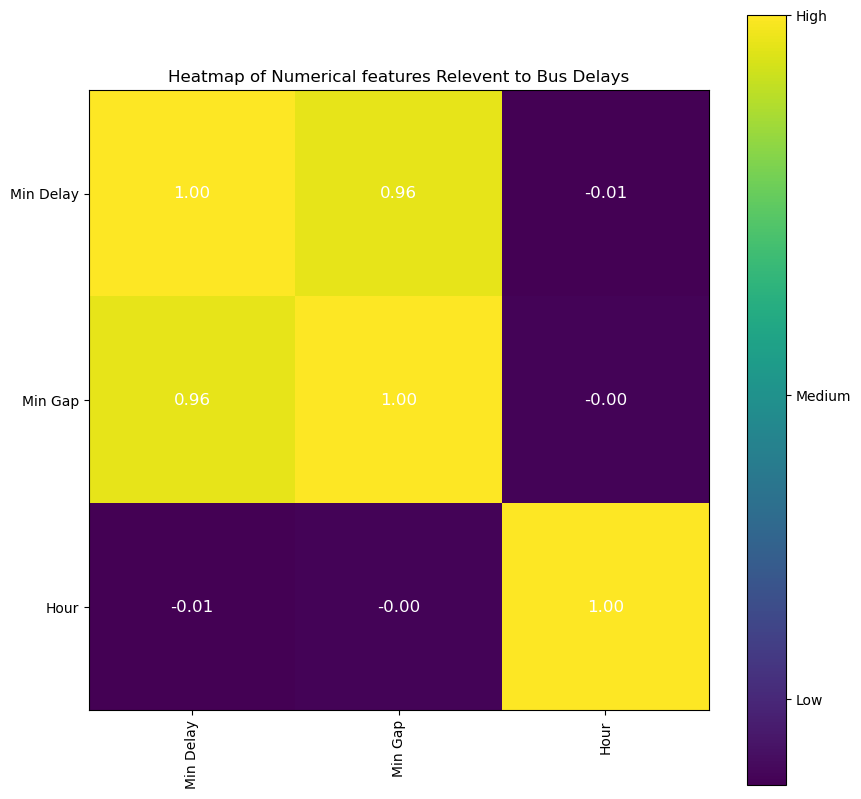

In [11]:
correlation = delay_dataset[['Min Delay', 'Min Gap', 'Hour']].corr()

correlation_matrix = correlation.values

plt.figure(figsize=(10, 10))

# Adding values to the heatmap
for i in range(correlation.shape[0]):
    for j in range(correlation.shape[1]):
        plt.text(j, i, f'{correlation_matrix[i, j]:.2f}', ha='center', va='center', color='w', fontsize=12)

plt.imshow(correlation, cmap='viridis', interpolation='nearest')

cbar = plt.colorbar(ticks=[0.1, 0.5, 1])
cbar.ax.set_yticklabels(['Low', 'Medium', 'High'])

plt.xticks(range(len(correlation.columns)),correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title('Heatmap of Numerical features Relevent to Bus Delays')
plt.show()

## **9. Heatmap of Median TTC Bus Delays by Day and Time Period**

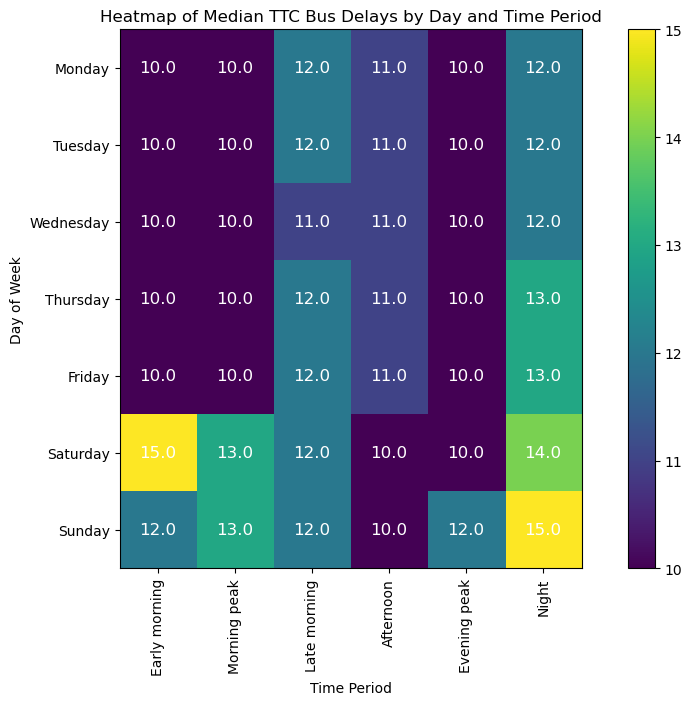

In [15]:
# Calculate median delay for each day and time period
heatmap_data = delay_dataset.pivot_table(
    index='Day',
    columns='Time_Period',
    values='Min Delay',
    aggfunc='median'
)

# Arrange days and time periods in chronological order
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

period_order = [
    'Early morning', 'Morning peak', 'Late morning',
    'Afternoon', 'Evening peak', 'Night'
]

heatmap_data = heatmap_data.reindex(
    index=day_order,
    columns=period_order
)

heatmap_matrix = heatmap_data.values

plt.figure(figsize=(12, 7))

# Add median delay values to the heatmap
# Adding values to the heatmap
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        plt.text(j, i, f'{heatmap_matrix[i, j]}', ha='center', va='center', color='w', fontsize=12)

plt.imshow(heatmap_data, cmap='viridis', interpolation='nearest')

cbar = plt.colorbar()

plt.xticks(range(len(heatmap_data.columns)),heatmap_data.columns, rotation=90)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)

plt.xlabel('Time Period')
plt.ylabel('Day of Week')

plt.title('Heatmap of Median TTC Bus Delays by Day and Time Period')
plt.show()